# Preprocessing sonic log Data
This notebook is used to homogenize the sonic log data for training the Gaussian Process Model

# Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams as rc
import matplotlib
import math
import matplotlib.colors as mcolors
import os
import torch
import gpytorch
from pyproj import Proj, transform
from sklearn.preprocessing import StandardScaler
import linear_operator
import lasio
from pyproj import Transformer
from pygam import LinearGAM

configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Times New Roman'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 14,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

dir_fig = '../Data/Figure/'

# Moving median function

In [3]:
def moving_median(x, y, w):
    x = np.asarray(x)
    y = np.asarray(y)
    x_min = np.min(x)
    x_max = np.max(x)
    step = w / 2
    medians = []
    start = x_min
    while start + w <= x_max:
        end = start + w
        center = (start + end) / 2
        mask = (x >= start) & (x < end)
        if np.any(mask):
            median_val = np.median(y[mask])
            medians.append((center, median_val))
        start += step
    return pd.DataFrame(medians, columns=['DEPTH_m', 'velocity_mps'])

In [5]:
excel_path = '../Data/Raw_data/log_data/LA_downtown_wells_for_Kim.xlsx'
df_more = pd.read_excel(excel_path)
df_more['TVDSS'] = -df_more['Z']
df_more.rename(columns={'WELLNAME': 'source_file', 'MD': 'DEPTH', 'itt_dig': 'ITT_DIG'}, inplace=True)
df_more["velocity_mps"] = 1e6 / df_more["ITT_DIG"] * 0.3048
df_more["DEPTH_m"] = df_more["DEPTH"] * 0.3048
df_more.drop(columns=['Z'], inplace=True)
df_more

,source_file,X,Y,DEPTH,ITT_DIG,TVDSS,velocity_mps,DEPTH_m
0,sobudd_1,388094.4688,3764796.922,1400.0,157.298,354.720001,1937.723302,426.7200
1,sobudd_1,388094.4688,3764796.922,1400.5,157.101,354.872406,1940.153150,426.8724
2,sobudd_1,388094.4688,3764796.922,1401.0,156.903,355.024811,1942.601480,427.0248
3,sobudd_1,388094.4688,3764796.922,1401.5,156.509,355.177216,1947.491838,427.1772
4,sobudd_1,388094.4688,3764796.922,1402.0,156.114,355.329620,1952.419386,427.3296
...,...,...,...,...,...,...,...,...
168928,sovc_1,383593.3125,3766747.703,5298.5,95.435,1540.982788,3193.796825,1614.9828
168929,sovc_1,383593.3125,3766747.703,5299.0,95.435,1541.135254,3193.796825,1615.1352
168930,sovc_1,383593.3125,3766747.703,5299.5,95.652,1541.287598,3186.551248,1615.2876
168931,sovc_1,383593.3125,3766747.703,5300.0,95.435,1541.440063,3193.796825,1615.4400


In [6]:
desktop_path = os.path.join("../Data/Raw_data/log_data")
las_filenames = [
    "HVD_CVMH_soccom_1.las",
    "HVD_CVMH_sooc_1.las",
    "HVD_CVMH_timc_1.las",
    "HVD_CVMH_uolt_1c.las",
    "HVD_CVMH_uolt_1r.las",
]

df_list = []

for filename in las_filenames:
    las_path = os.path.join(desktop_path, filename)
    las = lasio.read(las_path)
    df = las.df().reset_index()

    df["source_file"] = filename
    df["velocity_mps"] = 1e6 / df["ITT_DIG"] * 0.3048
    df["DEPTH_m"] = df["DEPTH"] * 0.3048

    df_list.append(df)

df_combined_five = pd.concat(df_list, ignore_index=True)
df_combined_five

,DEPTH,X,Y,TVDSS,ITT_DIG,source_file,velocity_mps,DEPTH_m
0,110.000000,387402.000,3753149.50,33.528000,184.352997,HVD_CVMH_soccom_1.las,1653.349850,33.528000
1,110.500000,387402.000,3753149.50,33.680401,184.712006,HVD_CVMH_soccom_1.las,1650.136375,33.680400
2,111.000008,387402.000,3753149.50,33.832802,185.072006,HVD_CVMH_soccom_1.las,1646.926548,33.832802
3,111.500000,387402.000,3753149.50,33.985199,185.251999,HVD_CVMH_soccom_1.las,1645.326375,33.985200
4,112.000000,387402.000,3753149.50,34.137600,185.612000,HVD_CVMH_soccom_1.las,1642.135207,34.137600
...,...,...,...,...,...,...,...,...
93197,9487.500000,382795.562,3761977.67,2836.790040,92.772003,HVD_CVMH_uolt_1r.las,3285.473952,2891.790000
93198,9488.000000,382795.562,3761977.67,2836.942380,92.573998,HVD_CVMH_uolt_1r.las,3292.501223,2891.942400
93199,9488.500000,382795.562,3761977.67,2837.094970,92.573998,HVD_CVMH_uolt_1r.las,3292.501223,2892.094800
93200,9489.000000,382795.562,3761977.67,2837.247310,92.376000,HVD_CVMH_uolt_1r.las,3299.558345,2892.247200


In [7]:
df_combined_raw = pd.concat([df_more, df_combined_five], ignore_index=True)
df_combined_raw

,source_file,X,Y,DEPTH,ITT_DIG,TVDSS,velocity_mps,DEPTH_m
0,sobudd_1,388094.4688,3764796.922,1400.0,157.298000,354.720001,1937.723302,426.7200
1,sobudd_1,388094.4688,3764796.922,1400.5,157.101000,354.872406,1940.153150,426.8724
2,sobudd_1,388094.4688,3764796.922,1401.0,156.903000,355.024811,1942.601480,427.0248
3,sobudd_1,388094.4688,3764796.922,1401.5,156.509000,355.177216,1947.491838,427.1772
4,sobudd_1,388094.4688,3764796.922,1402.0,156.114000,355.329620,1952.419386,427.3296
...,...,...,...,...,...,...,...,...
262130,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9487.5,92.772003,2836.790040,3285.473952,2891.7900
262131,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9488.0,92.573998,2836.942380,3292.501223,2891.9424
262132,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9488.5,92.573998,2837.094970,3292.501223,2892.0948
262133,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9489.0,92.376000,2837.247310,3299.558345,2892.2472


In [8]:
df_combined_raw.drop( np.argwhere( df_combined_raw['ITT_DIG'].isna() )[:,0], inplace=True )
df_combined_raw
#df_combined_raw = df_combined_raw[df_combined_raw['DEPTH_m'] <= 1000]
df_combined_raw

,source_file,X,Y,DEPTH,ITT_DIG,TVDSS,velocity_mps,DEPTH_m
0,sobudd_1,388094.4688,3764796.922,1400.0,157.298000,354.720001,1937.723302,426.7200
1,sobudd_1,388094.4688,3764796.922,1400.5,157.101000,354.872406,1940.153150,426.8724
2,sobudd_1,388094.4688,3764796.922,1401.0,156.903000,355.024811,1942.601480,427.0248
3,sobudd_1,388094.4688,3764796.922,1401.5,156.509000,355.177216,1947.491838,427.1772
4,sobudd_1,388094.4688,3764796.922,1402.0,156.114000,355.329620,1952.419386,427.3296
...,...,...,...,...,...,...,...,...
262130,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9487.5,92.772003,2836.790040,3285.473952,2891.7900
262131,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9488.0,92.573998,2836.942380,3292.501223,2891.9424
262132,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9488.5,92.573998,2837.094970,3292.501223,2892.0948
262133,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9489.0,92.376000,2837.247310,3299.558345,2892.2472


In [9]:
window_size = 20.
avg_profiles = []

for name, group in df_combined_raw.groupby("source_file"):
    smoothed = moving_median(group["DEPTH_m"], group["velocity_mps"], window_size)
    
    smoothed["X"] = group["X"].iloc[0]
    smoothed["Y"] = group["Y"].iloc[0]
    smoothed["source_file"] = name
    smoothed['TVDSS'] = smoothed['DEPTH_m'] + group['TVDSS'].iloc[0] - group['DEPTH_m'].iloc[0]
    avg_profiles.append(smoothed)

df_avg_combined = pd.concat(avg_profiles, ignore_index=True)

In [10]:
#df_avg_combined = df_avg_combined[df_avg_combined['DEPTH_m'] <= 1000]
df_avg_combined

,DEPTH_m,velocity_mps,X,Y,source_file,TVDSS
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000
...,...,...,...,...,...,...
3943,2136.3772,3271.509531,387298.0938,3767711.984,tuo_2,2053.377197
3944,2146.3772,3371.830612,387298.0938,3767711.984,tuo_2,2063.377197
3945,2156.3772,3429.633928,387298.0938,3767711.984,tuo_2,2073.377197
3946,2166.3772,3412.144009,387298.0938,3767711.984,tuo_2,2083.377197


In [11]:
df_avg_combined['source_file'].unique()

array(['HVD_CVMH_soccom_1.las', 'HVD_CVMH_sooc_1.las',
       'HVD_CVMH_timc_1.las', 'HVD_CVMH_uolt_1c.las',
       'HVD_CVMH_uolt_1r.las', 'arsj_11', 'arsj_11r', 'arsj_14',
       'arsj_16', 'arsj_18', 'arsj_20', 'arsj_5', 'arsj_8', 'arwa_1',
       'rowa_2', 'sobc_1', 'sobd_1a', 'sobudd_1', 'soccs_1', 'soech_1',
       'sofc_1', 'sofcch_1', 'soflc_1', 'sog_4a', 'sog_6', 'sokc_1',
       'sokc_1r', 'sosa_1', 'souc_1', 'sovc_1', 'sowc_1', 'sowc_2',
       'tuo_2'], dtype=object)

In [12]:
source_counts = df_avg_combined.groupby('source_file').size().reset_index(name='count')
print(source_counts)

              source_file  count
0   HVD_CVMH_soccom_1.las    464
1     HVD_CVMH_sooc_1.las    238
2     HVD_CVMH_timc_1.las    174
3    HVD_CVMH_uolt_1c.las    279
4    HVD_CVMH_uolt_1r.las    257
5                 arsj_11     96
6                arsj_11r     34
7                 arsj_14     75
8                 arsj_16     44
9                 arsj_18     34
10                arsj_20     33
11                 arsj_5     48
12                 arsj_8     81
13                 arwa_1     45
14                 rowa_2    103
15                 sobc_1     95
16                sobd_1a    155
17               sobudd_1    276
18                soccs_1    133
19                soech_1    138
20                 sofc_1    181
21               sofcch_1     49
22                soflc_1     91
23                 sog_4a     69
24                  sog_6     59
25                 sokc_1     24
26                sokc_1r    158
27                 sosa_1    142
28                 souc_1     71
29        

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

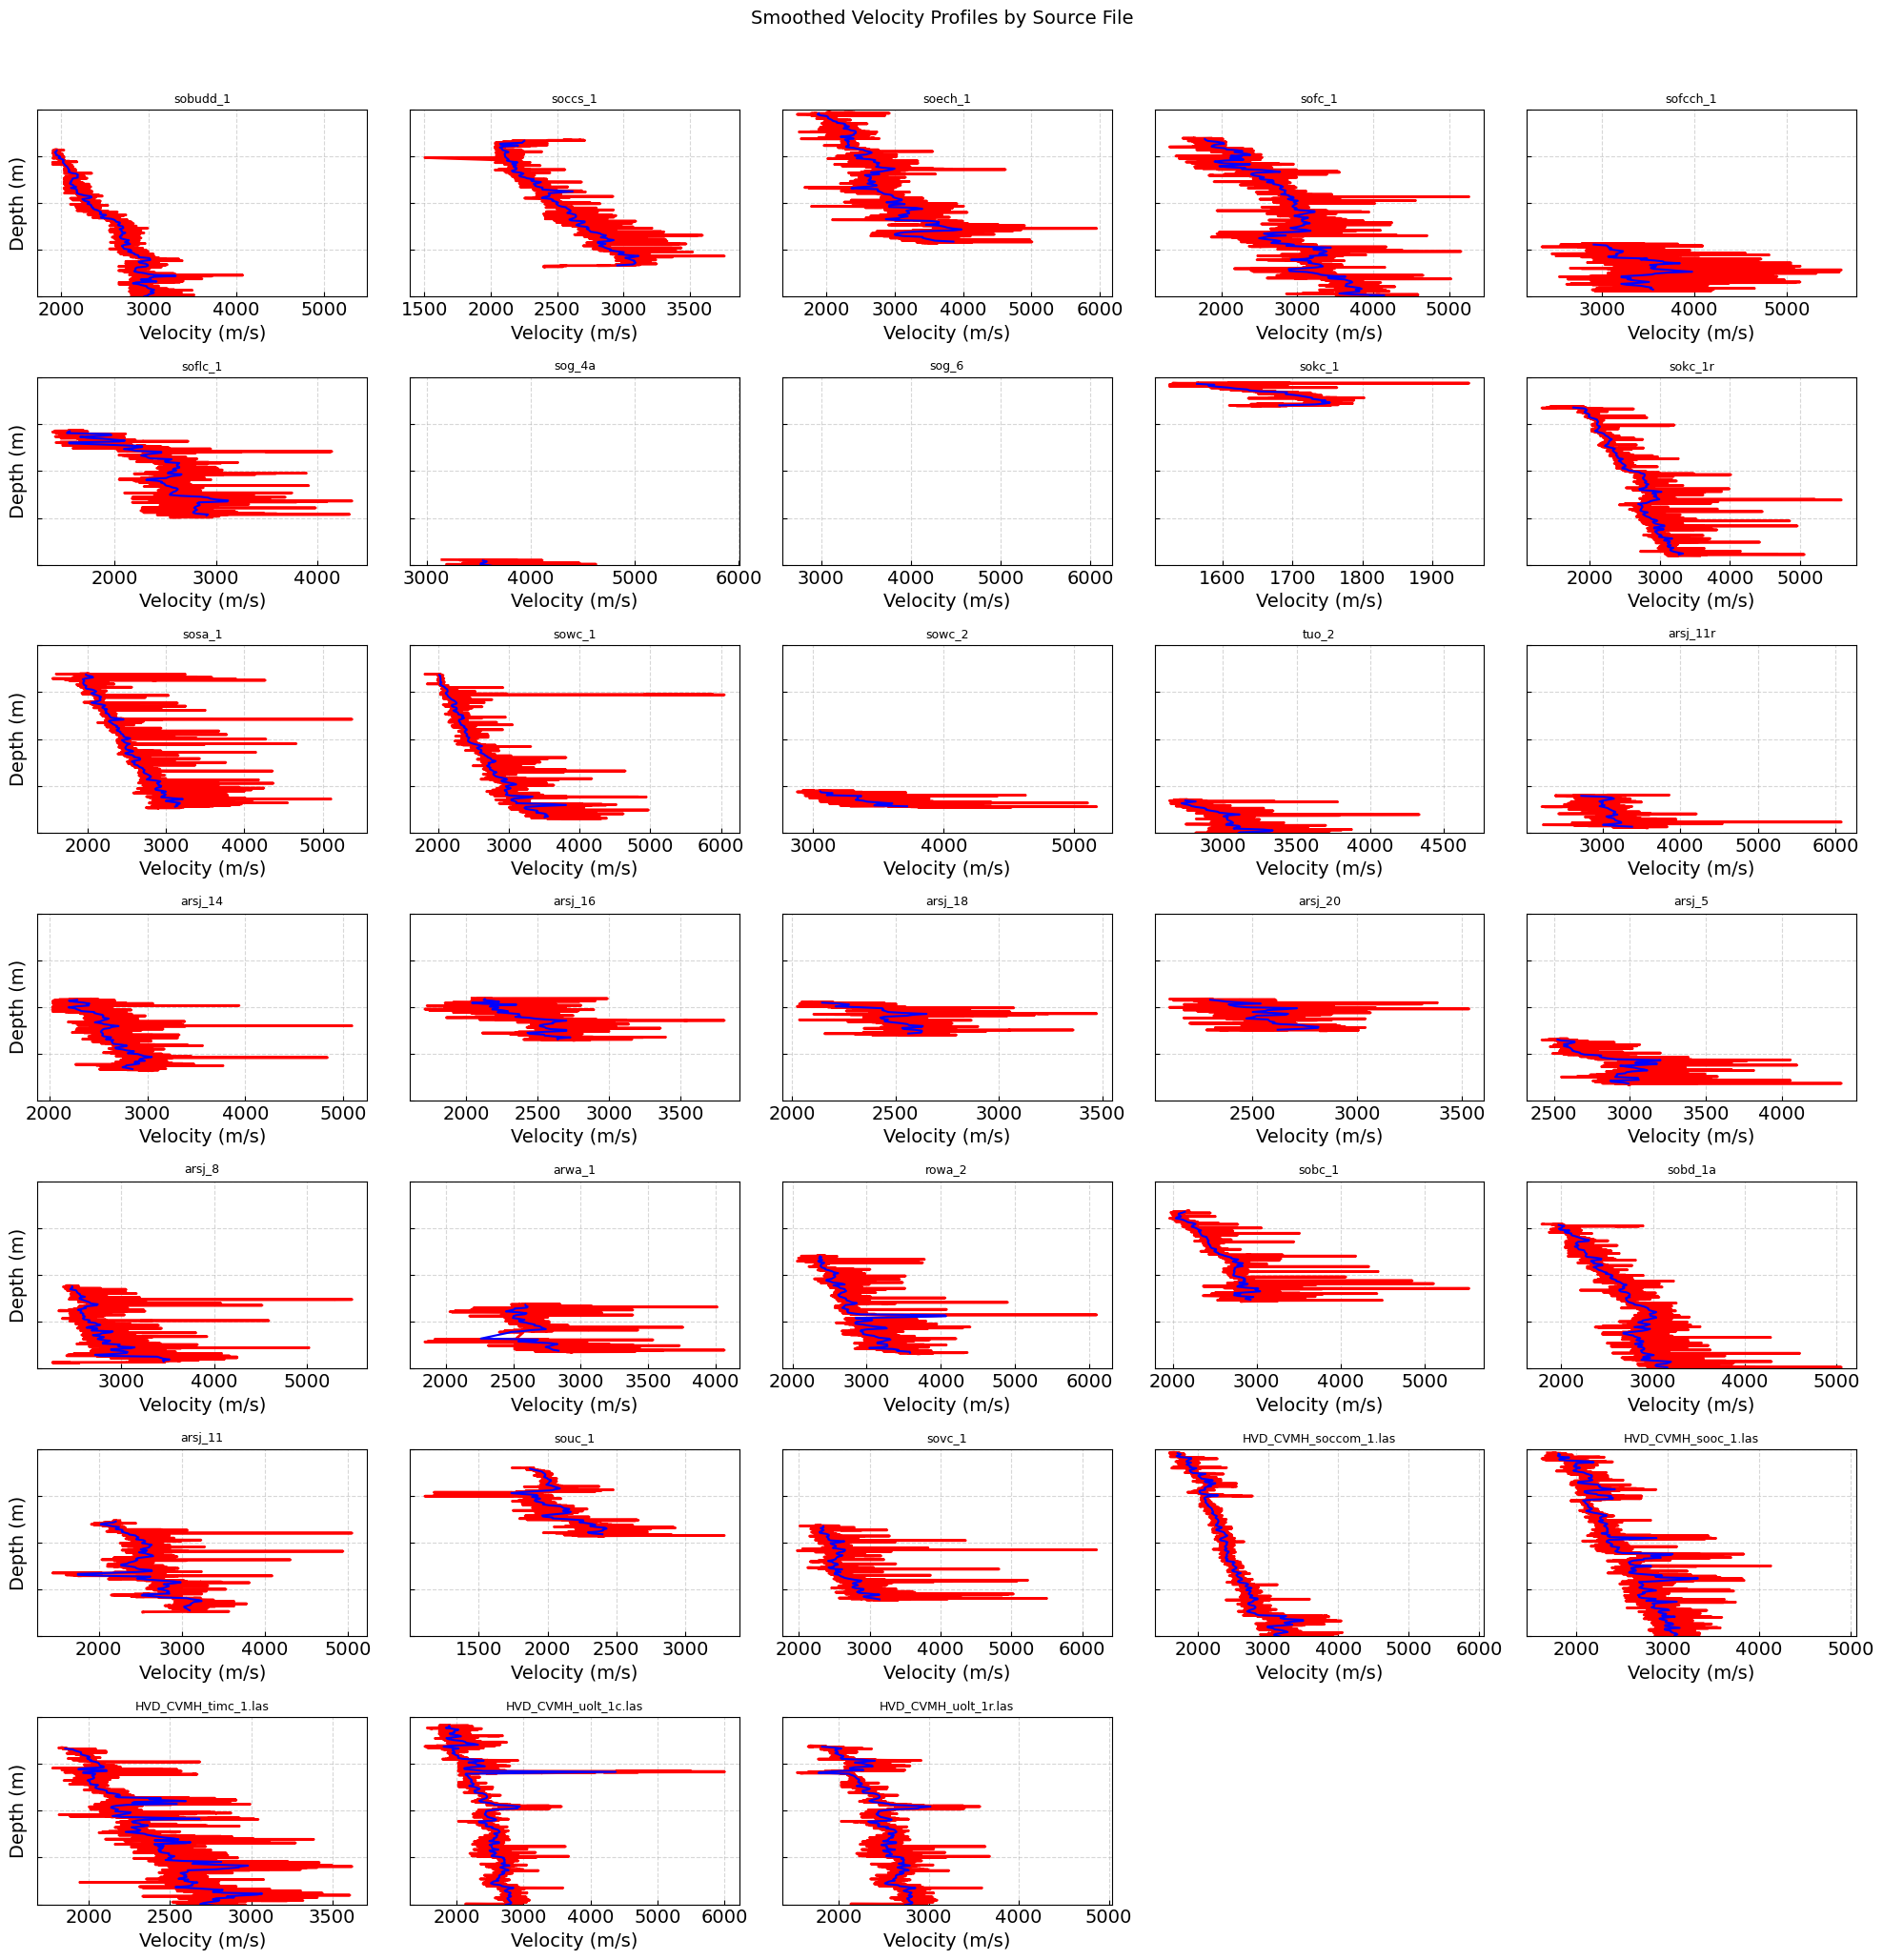

In [13]:
source_list = df_combined_raw['source_file'].unique()
n = len(source_list)
ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols * 4, nrows * 3), sharey=True)

for i, source in enumerate(source_list):
    row, col = divmod(i, ncols)
    ax = axes[row, col]

    subset = df_avg_combined[df_avg_combined['source_file'] == source]
    subset2 = df_combined_raw[df_combined_raw['source_file'] == source]

    ax.plot(subset2['velocity_mps'], subset2['DEPTH_m'], color='r', linewidth=2, label='raw')
    ax.plot(subset['velocity_mps'], subset['DEPTH_m'], color='b', label='smoothed')

    ax.set_ylim(0, 2000)
    ax.invert_yaxis()
    ax.set_title(source, fontsize=9)
    ax.set_xlabel('Velocity (m/s)')
    if col == 0:
        ax.set_ylabel('Depth (m)')
    else:
        ax.set_yticklabels([])

for j in range(i + 1, nrows * ncols):
    row, col = divmod(j, ncols)
    fig.delaxes(axes[row, col])

plt.suptitle("Smoothed Velocity Profiles by Source File", fontsize=14)
plt.tight_layout()
plt.subplots_adjust(top=0.93)
plt.show()


findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

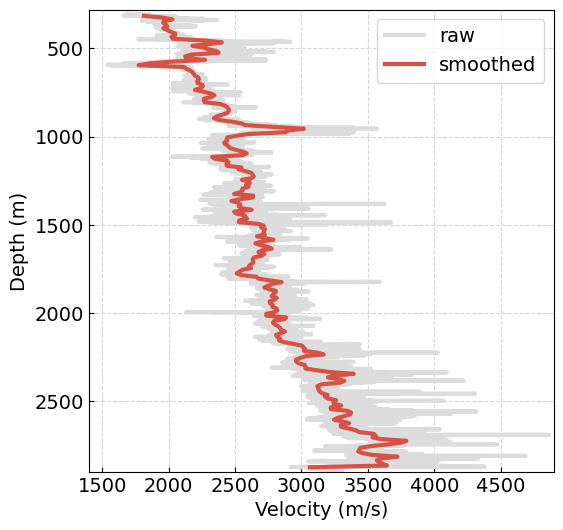

In [14]:
subset = df_avg_combined[df_avg_combined['source_file'] == 'HVD_CVMH_uolt_1r.las']
subset2 = df_combined_raw[df_combined_raw['source_file'] == 'HVD_CVMH_uolt_1r.las']


fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(subset2['velocity_mps'], subset2['DEPTH_m'], color=gray_color, linewidth=3, label='raw')
ax.plot(subset['velocity_mps'], subset['DEPTH_m'], color=red_color, linewidth=3, label='smoothed')

ax.set( xlim=(1400, 4900), ylim=(280, 2900),
       xlabel="Velocity (m/s)",
       ylabel="Depth (m)")
ax.invert_yaxis()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

ax.legend()

# Regression

  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
  9% (1 of 11) |##                       | Elapsed Time: 0:00:00 ETA:   0:00:01
 18% (2 of 11) |####                     | Elapsed Time: 0:00:00 ETA:   0:00:01
 27% (3 of 11) |######                   | Elapsed Time: 0:00:00 ETA:   0:00:00
 36% (4 of 11) |#########                | Elapsed Time: 0:00:00 ETA:   0:00:00
 45% (5 of 11) |###########              | Elapsed Time: 0:00:00 ETA:   0:00:00
 54% (6 of 11) |#############            | Elapsed Time: 0:00:00 ETA:   0:00:00
 63% (7 of 11) |###############          | Elapsed Time: 0:00:00 ETA:   0:00:00
 72% (8 of 11) |##################       | Elapsed Time: 0:00:00 ETA:   0:00:00
 81% (9 of 11) |####################     | Elapsed Time: 0:00:00 ETA:   0:00:00
 90% (10 of 11) |#####################   | Elapsed Time: 0:00:00 ETA:   0:00:00
100% (11 of 11) |########################| Elapsed Time: 0:00:01 Time:  0:00:01
  0% (0 of 11) |                        

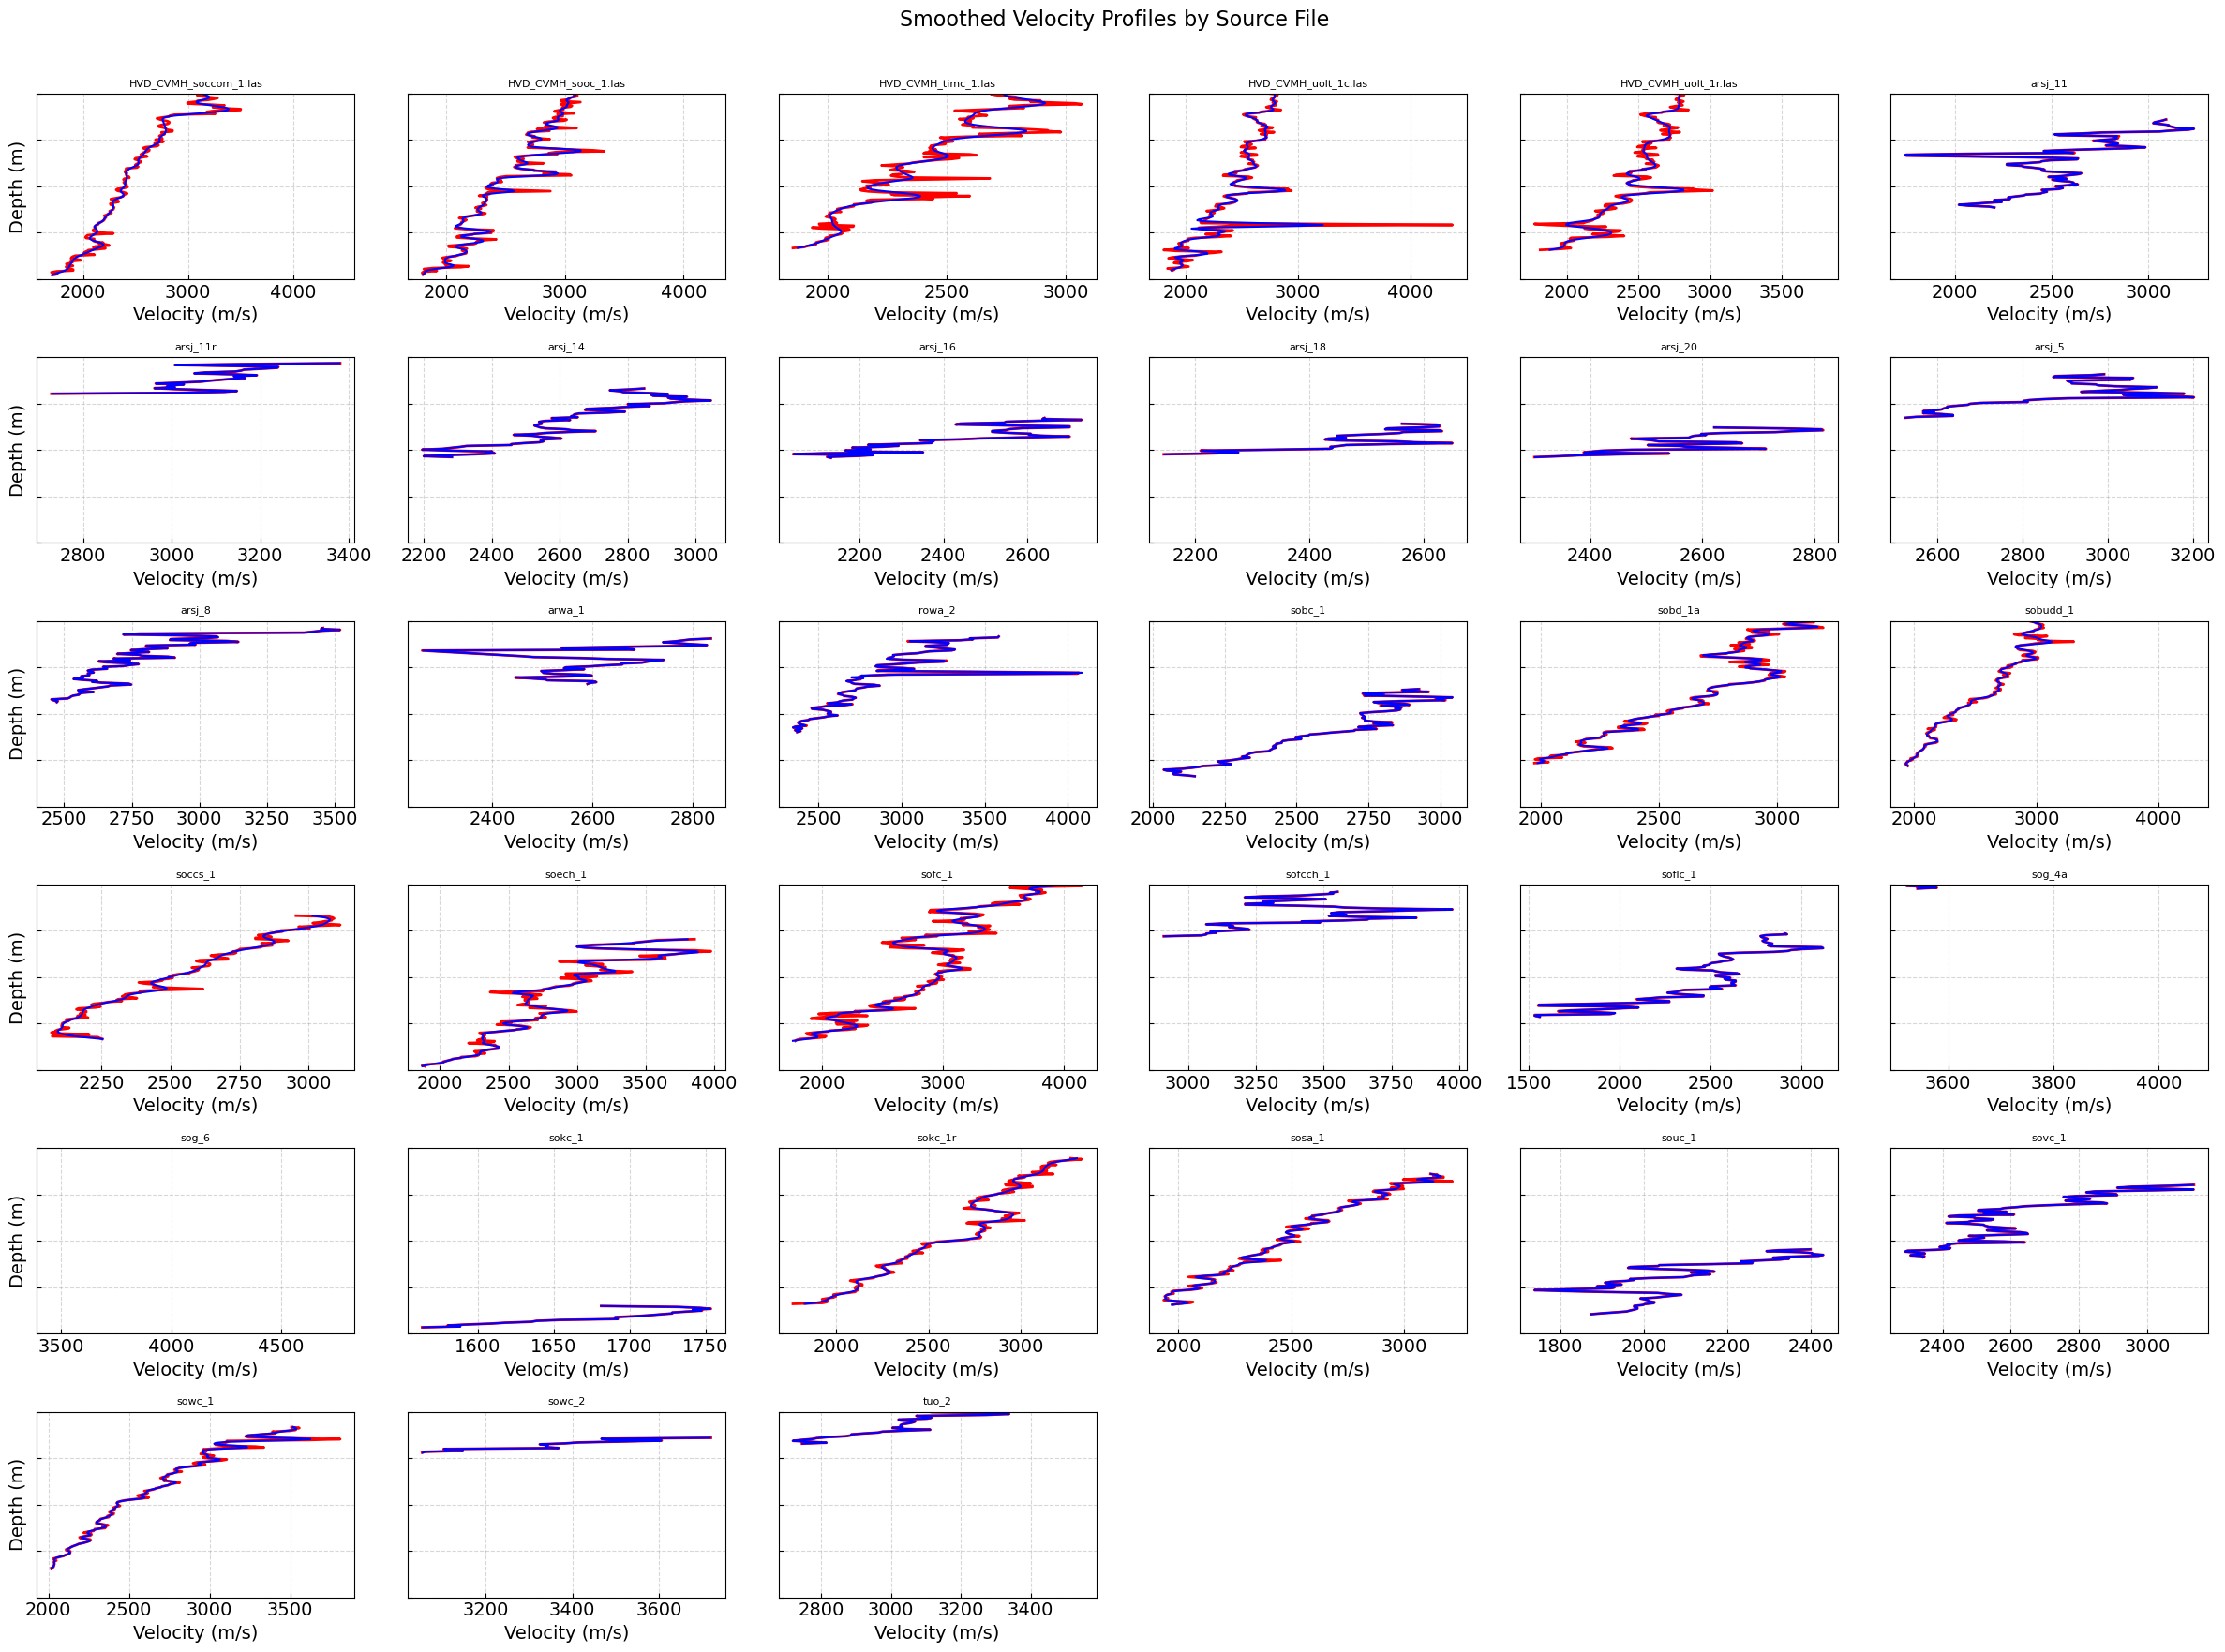

In [15]:
df_avg_combined['velocity'] = np.nan  

source_list = df_avg_combined['source_file'].unique()
n = len(source_list)

ncols = 6
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols * 4, nrows * 3), sharey=True)
axes = axes.flatten()

for i, source in enumerate(source_list):
    ax = axes[i]
    subset = df_avg_combined[df_avg_combined['source_file'] == source]

    if subset.empty:
        ax.axis('off')
        continue

    z = subset['DEPTH_m'].values.reshape(-1, 1)
    y = subset['velocity_mps'].values

    gam = LinearGAM(n_splines=100).gridsearch(z, y)
    y_smooth = gam.predict(z)

    df_avg_combined.loc[subset.index, 'velocity'] = y_smooth
    ax.plot(subset['velocity_mps'], subset['DEPTH_m'], color='r', linewidth=2, label='original')
    ax.plot(y_smooth, subset['DEPTH_m'], color='b', label='smoothed')

    ax.set_ylim(0, 2000)
    ax.set_title(source, fontsize=8)
    ax.set_xlabel('Velocity (m/s)')
    if i % ncols == 0:
        ax.set_ylabel('Depth (m)')
    else:
        ax.set_yticklabels([])

for j in range(i + 1, nrows * ncols):
    axes[j].axis('off')

plt.suptitle("Smoothed Velocity Profiles by Source File", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.93)
plt.show()


findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

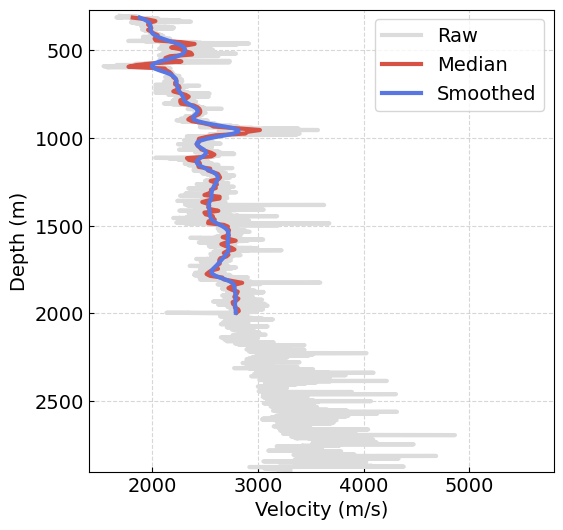

In [21]:
subset = df_avg_combined[df_avg_combined['source_file'] == 'HVD_CVMH_uolt_1r.las']
subset2 = df_combined_raw[df_combined_raw['source_file'] == 'HVD_CVMH_uolt_1r.las']


fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(subset2['velocity_mps'], subset2['DEPTH_m'], color=gray_color, linewidth=3, label='Raw')
ax.plot(subset['velocity_mps'], subset['DEPTH_m'], color=red_color, linewidth=3, label='Median')
ax.plot(subset['velocity'], subset['DEPTH_m'], color=blue_color, linewidth=3, label='Smoothed')

ax.set( xlim=(1400, 5800), ylim=(270, 2900),
       xlabel="Velocity (m/s)",
       ylabel="Depth (m)")
ax.invert_yaxis()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

ax.legend()
#fig.savefig(dir_fig+'vs_log_cleaned.png', format='png', dpi=300)

In [22]:
df_avg_combined

,DEPTH_m,velocity_mps,X,Y,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748
...,...,...,...,...,...,...,...,...,...,...
3925,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045
3926,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045
3927,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045
3928,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045


In [23]:
df_avg_combined = df_avg_combined[df_avg_combined['DEPTH_m'] <= 2000]
df_avg_combined

,DEPTH_m,velocity_mps,X,Y,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748
...,...,...,...,...,...,...,...,...,...,...
3925,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045
3926,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045
3927,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045
3928,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045


### Convert to SI Units and get information from UCVM

In [24]:
source_to_id = {
    'arsj_11': -1,     
    'arsj_11r': -2,
    'arsj_14': -3,
    'arsj_16': -4,
    'arsj_18': -5,
    'arsj_20': -6,
    'arsj_5': -7,
    'arsj_8': -8,
    'arwa_1': -9,
    'rowa_2': -10,
    'sobc_1': -11,
    'sobd_1a': -12,
    'sobudd_1': -13,
    'soccs_1': -14,
    'soech_1': -15,
    'sofc_1': -16,
    'sofcch_1': -17,
    'soflc_1': -18,
    'sog_4a': -19,
    'sog_6': -20,
    'sokc_1': -21,
    'sokc_1r': -22,
    'sosa_1': -23,
    'souc_1': -24,
    'sovc_1': -25,
    'sowc_1': -26,
    'sowc_2': -27,
    'tuo_2': -28,
    'HVD_CVMH_soccom_1.las': -29,
    'HVD_CVMH_sooc_1.las': -30,
    'HVD_CVMH_timc_1.las': -31,
    'HVD_CVMH_uolt_1c.las': -32,
    'HVD_CVMH_uolt_1r.las': -33,
}
df_avg_combined['velocity_metadata_id'] = df_avg_combined['source_file'].map(source_to_id)

In [25]:
transformer = Transformer.from_crs("epsg:32611", "epsg:4326", always_xy=True)
longitudes, latitudes = transformer.transform(df_avg_combined['X'].values, df_avg_combined['Y'].values)
df_avg_combined.loc[:,'longitude'] = longitudes
df_avg_combined.loc[:,'latitude'] = latitudes
df_avg_combined

,DEPTH_m,velocity_mps,X,Y,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748
...,...,...,...,...,...,...,...,...,...,...
3925,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045
3926,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045
3927,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045
3928,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045


In [28]:
with open('../Data/Vel_data/Preprocessing_log/'+'sonic_test_input.txt', "w", encoding="utf-8") as file:
    for idx, row in df_avg_combined[['longitude', 'latitude', 'DEPTH_m']].iterrows():
        file.write(f"{row['longitude']} {row['latitude']} {row['DEPTH_m']}\n")

In [29]:
df_ucvm_info = pd.read_csv('../Data/Vel_data/Preprocessing_log/'+'sonic_test_output.txt', sep=r'\s+', 
                      header=None)
vs = df_ucvm_info[7].values
vp = df_ucvm_info[6].values
surf_elevation = df_ucvm_info[3].values

In [30]:
df_avg_combined.loc[:,'vs_UCVM'] = vs
df_avg_combined.loc[:,'vp_UCVM'] = vp
df_avg_combined.loc[:,'surf_elevation'] = surf_elevation
df_avg_combined.loc[:,'ratio'] = df_avg_combined['vs_UCVM']/df_avg_combined['vp_UCVM']
df_avg_combined.loc[:,'vs'] = df_avg_combined['ratio']*df_avg_combined['velocity']
df_avg_combined

,DEPTH_m,velocity_mps,X,Y,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude,vs_UCVM,vp_UCVM,surf_elevation,ratio,vs
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748,867.819,1684.427,23.596,0.515201,877.096827
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748,871.262,1692.589,23.596,0.514751,887.092079
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748,874.706,1700.750,23.596,0.514306,900.107703
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748,878.150,1708.912,23.596,0.513865,914.273689
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748,881.593,1717.073,23.596,0.513428,927.728573
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3925,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045,2107.562,3453.733,83.353,0.610227,1875.053977
3926,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045,2115.348,3464.896,83.353,0.610508,1998.798374
3927,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045,2123.133,3476.058,83.353,0.610788,2038.966008
3928,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045,2130.919,3487.221,83.353,0.611065,2026.579456


In [31]:
df_avg_combined.loc[:,'depth'] = df_avg_combined.loc[:,'TVDSS'] + df_avg_combined.loc[:,'surf_elevation']

In [32]:
df_avg_combined

,DEPTH_m,velocity_mps,X,Y,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude,vs_UCVM,vp_UCVM,surf_elevation,ratio,vs,depth
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748,867.819,1684.427,23.596,0.515201,877.096827,67.124000
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748,871.262,1692.589,23.596,0.514751,887.092079,77.124000
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748,874.706,1700.750,23.596,0.514306,900.107703,87.124000
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748,878.150,1708.912,23.596,0.513865,914.273689,97.124000
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748,881.593,1717.073,23.596,0.513428,927.728573,107.124000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3925,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045,2107.562,3453.733,83.353,0.610227,1875.053977,1956.730197
3926,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045,2115.348,3464.896,83.353,0.610508,1998.798374,1966.730197
3927,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045,2123.133,3476.058,83.353,0.610788,2038.966008,1976.730197
3928,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045,2130.919,3487.221,83.353,0.611065,2026.579456,1986.730197


In [33]:
with open('../Data/Vel_data/Preprocessing_log/'+'sonic_elevation_input.txt', "w", encoding="utf-8") as file:
    for idx, row in df_avg_combined[['longitude', 'latitude']].iterrows():
        file.write(f"{row['longitude']} {row['latitude']} \n")

In [34]:
df_ucvm_info_z = pd.read_csv('../Data/Vel_data/Preprocessing_log/'+'sonic_elevation_output.txt', sep=r'\s+', 
                      header=None)
df_avg_combined.loc[:,'Z_2.5'] = df_ucvm_info_z[2].values

In [35]:
df_avg_combined.loc[:,'diff'] = np.log(df_avg_combined['vs']) - np.log(df_avg_combined['vs_UCVM'])

In [36]:
df_avg_combined

,DEPTH_m,velocity_mps,X,Y,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude,vs_UCVM,vp_UCVM,surf_elevation,ratio,vs,depth,Z_2.5,diff
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748,867.819,1684.427,23.596,0.515201,877.096827,67.124000,4400.0,0.010634
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748,871.262,1692.589,23.596,0.514751,887.092079,77.124000,4400.0,0.018006
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748,874.706,1700.750,23.596,0.514306,900.107703,87.124000,4400.0,0.028627
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748,878.150,1708.912,23.596,0.513865,914.273689,97.124000,4400.0,0.040313
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748,881.593,1717.073,23.596,0.513428,927.728573,107.124000,4400.0,0.051009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3925,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045,2107.562,3453.733,83.353,0.610227,1875.053977,1956.730197,2500.0,-0.116894
3926,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045,2115.348,3464.896,83.353,0.610508,1998.798374,1966.730197,2500.0,-0.056673
3927,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045,2123.133,3476.058,83.353,0.610788,2038.966008,1976.730197,2500.0,-0.040450
3928,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045,2130.919,3487.221,83.353,0.611065,2026.579456,1986.730197,2500.0,-0.050204


In [37]:
nan_rows = df_avg_combined[df_avg_combined['diff'].isna()]
print(nan_rows)

Empty DataFrame
Columns: [DEPTH_m, velocity_mps, X, Y, source_file, TVDSS, velocity, velocity_metadata_id, longitude, latitude, vs_UCVM, vp_UCVM, surf_elevation, ratio, vs, depth, Z_2.5, diff]
Index: []


# Show results

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

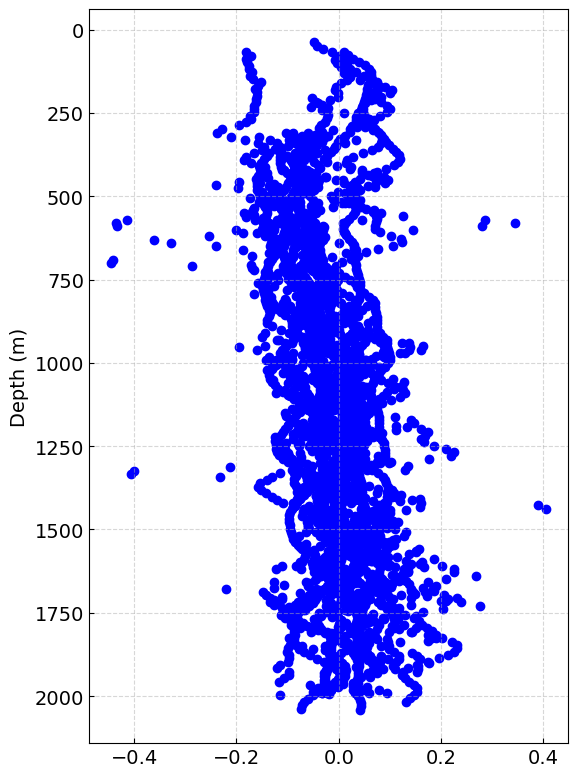

In [38]:
plt.figure(figsize=(6, 8))
plt.scatter(df_avg_combined['diff'], df_avg_combined['depth'], color='blue')
plt.gca().invert_yaxis()
#plt.xlabel(r'$\log(V_{S~Obs}) - \log(V_{S~UCVM})$')
plt.ylabel('Depth (m)')
# plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig(dir_fig+'vs_data_all.svg', format='svg', dpi=300)
#plt.savefig(dir_fig+'vs_data_all.png', format='png', dpi=300)
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

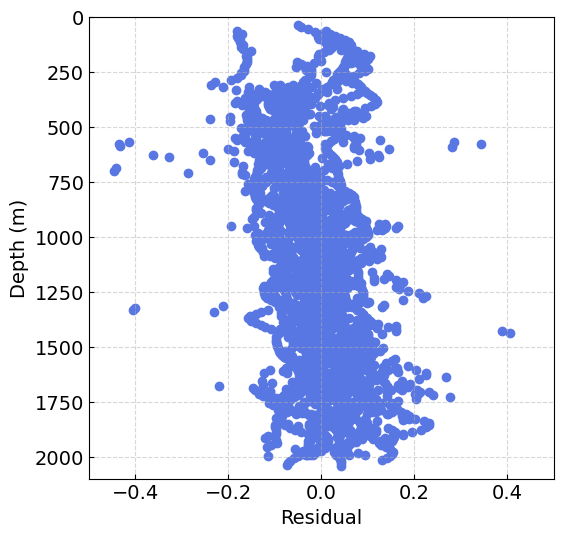

In [39]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.scatter(df_avg_combined['diff'], df_avg_combined['depth'],  color=blue_color)

ax.set( xlim=(-0.5, 0.5), ylim=(0, 2100),
       xlabel="Residual",
       ylabel="Depth (m)")
ax.invert_yaxis()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

#fig.savefig(dir_fig+'vs_log_data.png', format='png', dpi=300)

In [40]:
df_avg_combined.to_csv('../Data/Vel_data/Preprocessing_log/'+'vs_data_combined.txt', index=False,
                  encoding='utf-8',
                  lineterminator='\n')